- **Гипотеза 4.** На сколько можно увеличить прибыль если расположить парковки велосипедов рядом с торговыми точками (будто питание или сервис по велосипедам)

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- читаю файл csv "../../../data_additional/point_of_interest.csv"

In [2]:
point_of_interest = pd.read_csv('../../../data_additional/point_of_interest.csv')
point_of_interest

,start_station_id,category,name_build,start_lat,start_lng
0,30200,place_of_worship,Methodist Protestant Church,38.896501,-77.024143
1,30200,kindergarten,Georgetown Hill Early Childhood Center,38.895100,-77.023200
2,30200,kindergarten,Just Us Kids Child Development Center,38.894600,-77.020700
3,30200,theatre,Shakespeare Theatre Company - Klein Theater,38.895734,-77.022132
4,30200,cafe,Gregorys Coffee,38.895972,-77.021713
...,...,...,...,...,...
34392,33200,bench,NaN,38.894267,-77.038270
34393,33200,bench,NaN,38.897443,-77.036620
34394,33200,bench,NaN,38.897445,-77.036499
34395,33200,bench,NaN,38.896953,-77.036979


- смотрю уникальные категории точек интереса

In [3]:
data = [point for point in point_of_interest['category'].unique()]
data

['place_of_worship',
 'kindergarten',
 'theatre',
 'cafe',
 'bank',
 'tourist',
 'atm',
 'restaurant',
 'fast_food',
 'bar',
 'pub',
 'bicycle_rental',
 'post_box',
 'arts_centre',
 'drinking_water',
 'bench',
 'waste_basket',
 'language_school',
 'bicycle_parking',
 'fountain',
 'post_office',
 'toilets',
 'parking',
 'parking_entrance',
 'charging_station',
 'loading_dock',
 'school',
 'car_sharing',
 'cinema',
 'ice_cream',
 'car_rental',
 'border_control',
 'clinic',
 'marketplace',
 'motorcycle_parking',
 'vending_machine',
 'doctors',
 'cloakroom',
 'parcel_locker',
 'animal_boarding',
 'bicycle_repair_station',
 'recycling',
 'veterinary',
 'pharmacy',
 'childcare',
 'waste_disposal',
 'clock',
 'bureau_de_change',
 'dentist',
 'reception_desk',
 'fuel',
 'biergarten',
 'food_court',
 'public_bookcase',
 'fire_station',
 'table',
 'police',
 'marker',
 'social_facility',
 'library',
 'university',
 'post_depot',
 'parking_space',
 'social_centre',
 'bbq',
 'hookah_lounge',
 'vac

- используя AI собрал все точки относящиеся к еде или косвенно

In [4]:
food_categories = [
    "restaurant",
    "fast_food",
    "cafe",
    "food_court",
    "ice_cream",
    "catering",
    "bar",
    "pub",
    "biergarten",
    "hookah_lounge",
    "marketplace",
    "convenience",
    "drinking_water",
    "food_sharing",
    "watering_place",
    "bbq"
]

- оставляю только те точки которые входят в food_categories

In [5]:
food_categories = point_of_interest[point_of_interest['category'].isin(food_categories)]
food_categories

,start_station_id,category,name_build,start_lat,start_lng
4,30200,cafe,Gregorys Coffee,38.895972,-77.021713
8,30200,restaurant,minibar by José Andrés,38.896319,-77.023576
10,30200,fast_food,Jacks Famous Deli,38.894494,-77.020710
11,30200,fast_food,Potbelly,38.894289,-77.021418
13,30200,cafe,Starbucks,38.894168,-77.021712
...,...,...,...,...,...
34360,33200,fast_food,Chopt,38.898905,-77.040419
34361,33200,cafe,Starbucks,38.898857,-77.040261
34362,33200,cafe,Naan & Beyond,38.898792,-77.040089
34388,33200,restaurant,Immigrant Food,38.899282,-77.040078


- смотрю сколько получилось точек интереса (используя value_counts())

In [6]:
food_categories['category'].value_counts()

category
restaurant        4618
fast_food         2426
cafe              1500
bar                721
drinking_water     391
pub                246
ice_cream          192
marketplace         64
food_court          48
bbq                 46
catering            12
hookah_lounge       11
biergarten           6
food_sharing         1
watering_place       1
convenience          1
Name: count, dtype: int64

- делаю группировку по start_station_id и category, считаю количество name_build и сбрасываю индексы

In [7]:
count_food_builds = food_categories.groupby(['start_station_id', 'category'])['name_build'].count().reset_index()
count_food_builds

,start_station_id,category,name_build
0,30200,bar,4
1,30200,cafe,4
2,30200,drinking_water,0
3,30200,fast_food,10
4,30200,pub,1
...,...,...,...
2174,32608,marketplace,1
2175,32608,restaurant,3
2176,33200,cafe,9
2177,33200,fast_food,3


- делаю функцию которая группирует по start_station_id и считает сумму по name_build

In [8]:
def count_total_food(df):
    return df.groupby('start_station_id')['name_build'].sum()

- создаю словарь total_food_point

In [9]:
total_food_point = {}

- пишу цикл, который подсчитает сумму точек интереса

In [10]:
for station_id in count_food_builds['start_station_id'].unique():
    temp_df = count_food_builds[count_food_builds['start_station_id'] == station_id]
    total = count_total_food(temp_df)
    total_food_point[int(station_id)] = int(total.values[0])

- вывожу результат

In [11]:
total_food_point

{30200: 37,
 30201: 72,
 31000: 13,
 31001: 4,
 31002: 32,
 31003: 11,
 31004: 0,
 31005: 35,
 31006: 80,
 31007: 22,
 31009: 8,
 31010: 2,
 31011: 19,
 31012: 15,
 31013: 12,
 31014: 48,
 31015: 56,
 31016: 21,
 31017: 20,
 31018: 20,
 31019: 22,
 31020: 19,
 31021: 36,
 31022: 39,
 31023: 15,
 31024: 10,
 31025: 8,
 31026: 21,
 31027: 36,
 31028: 6,
 31029: 1,
 31030: 6,
 31031: 10,
 31032: 4,
 31033: 1,
 31034: 25,
 31035: 5,
 31036: 5,
 31037: 50,
 31038: 7,
 31039: 30,
 31040: 16,
 31041: 23,
 31042: 30,
 31043: 3,
 31044: 21,
 31045: 20,
 31046: 8,
 31047: 6,
 31048: 10,
 31049: 66,
 31050: 0,
 31051: 2,
 31052: 3,
 31053: 4,
 31055: 5,
 31057: 0,
 31058: 8,
 31060: 4,
 31061: 0,
 31062: 2,
 31065: 12,
 31066: 1,
 31067: 21,
 31068: 5,
 31069: 4,
 31071: 12,
 31073: 3,
 31074: 0,
 31075: 0,
 31076: 10,
 31077: 0,
 31079: 4,
 31081: 15,
 31082: 13,
 31083: 2,
 31084: 18,
 31085: 5,
 31086: 13,
 31087: 1,
 31088: 2,
 31089: 20,
 31091: 0,
 31092: 20,
 31094: 9,
 31097: 9,
 31098: 1

- добавляю столбец total_food_point

In [12]:
count_food_builds['total_food_point'] = count_food_builds['start_station_id'].apply(lambda x: total_food_point.get(x))

- вывожу результат

In [13]:
count_food_builds

,start_station_id,category,name_build,total_food_point
0,30200,bar,4,37
1,30200,cafe,4,37
2,30200,drinking_water,0,37
3,30200,fast_food,10,37
4,30200,pub,1,37
...,...,...,...,...
2174,32608,marketplace,1,8
2175,32608,restaurant,3,8
2176,33200,cafe,9,14
2177,33200,fast_food,3,14


- смотрю что будет если отсортировать по total_food_point

In [14]:
count_food_builds.sort_values(by='total_food_point')

,start_station_id,category,name_build,total_food_point
689,31240,drinking_water,0,0
403,31118,drinking_water,0,0
1588,31714,drinking_water,0,0
1589,31715,drinking_water,0,0
832,31273,drinking_water,0,0
...,...,...,...,...
743,31253,cafe,22,134
742,31253,bar,6,134
746,31253,pub,2,134
745,31253,food_court,4,134


- вывожу уникальные категории

In [15]:
count_food_builds['category'].unique()

<ArrowStringArray>
[           'bar',           'cafe', 'drinking_water',      'fast_food',
            'pub',     'restaurant',      'ice_cream',    'marketplace',
     'biergarten',     'food_court',            'bbq',  'hookah_lounge',
   'food_sharing', 'watering_place',       'catering',    'convenience']
Length: 16, dtype: str

- делаю сводную таблицу

In [16]:
count_food_builds_pivot = count_food_builds.pivot(columns='category', index='start_station_id', values='name_build')
count_food_builds_pivot

category,bar,bbq,biergarten,cafe,catering,convenience,drinking_water,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place
start_station_id,,,,,,,,,,,,,,,,
30200,4.0,NaN,NaN,4.0,NaN,NaN,0.0,10.0,NaN,NaN,NaN,NaN,NaN,1.0,18.0,NaN
30201,7.0,NaN,NaN,10.0,NaN,NaN,NaN,23.0,NaN,NaN,NaN,1.0,1.0,NaN,30.0,NaN
31000,NaN,NaN,NaN,5.0,NaN,NaN,0.0,3.0,NaN,NaN,NaN,1.0,NaN,1.0,3.0,NaN
31001,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN
31002,2.0,NaN,NaN,5.0,NaN,NaN,NaN,12.0,NaN,NaN,NaN,2.0,NaN,NaN,11.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32604,NaN,NaN,NaN,1.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,1.0,8.0,NaN
32605,NaN,NaN,NaN,1.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,1.0,NaN,4.0,NaN
32607,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN


- заменяю Nan на 0

In [17]:
count_food_builds_pivot = count_food_builds_pivot.replace(np.nan, 0)
count_food_builds_pivot

category,bar,bbq,biergarten,cafe,catering,convenience,drinking_water,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place
start_station_id,,,,,,,,,,,,,,,,
30200,4.0,0.0,0.0,4.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,1.0,18.0,0.0
30201,7.0,0.0,0.0,10.0,0.0,0.0,0.0,23.0,0.0,0.0,0.0,1.0,1.0,0.0,30.0,0.0
31000,0.0,0.0,0.0,5.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,0.0
31001,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
31002,2.0,0.0,0.0,5.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,2.0,0.0,0.0,11.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32604,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,8.0,0.0
32605,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,0.0
32607,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0


- считаю сумму и добавляю столбец total_food_point

In [18]:
count_food_builds_pivot['total_food_point'] = count_food_builds_pivot.sum(axis=1)

- читаю файл '../../../data_after_preprocessing/daily_rent_detail.parquet'

In [19]:
daily_rent_detail = pd.read_parquet("../../../data_after_preprocessing/daily_rent_detail.parquet")
daily_rent_detail

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_in_minutes
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,Anacostia Library,31804,11th & H St NE,31614,38.865784,-76.978401,38.899982,-76.991386,casual,1499.883301
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,10th & E St NW,31256,21st St & Constitution Ave NW,31261,38.895912,-77.026062,38.892460,-77.046570,member,24.483334
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,38.934265,-77.057976,38.916786,-77.028137,member,16.533333
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,38.934265,-77.057976,38.921074,-77.031883,casual,17.350000
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,38.902760,-77.038628,casual,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,117C27DBDD138B72,electric_bike,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,NaN,0,NaN,0,38.889999,-77.000000,38.889999,-77.000000,member,0.255800
16086668,4774F4D630258482,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,NaN,0,NaN,0,38.900002,-77.000000,38.869999,-76.949997,member,16.411934
16086669,D75836E25E77B5EC,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,NaN,0,NaN,0,38.919998,-76.989998,38.919998,-77.000000,member,6.182117
16086670,3B888603D18116DC,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,NaN,0,NaN,0,38.919998,-77.019997,38.919998,-77.029999,member,10.186934


- делаю merge c таблицей count_food_builds_pivot и daily_rent_detail

In [20]:
ride_a_bike_with_food_point = daily_rent_detail.merge(count_food_builds_pivot, how='inner', on='start_station_id')
ride_a_bike_with_food_point

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place,total_food_point
0,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,10th & E St NW,31256,21st St & Constitution Ave NW,31261,38.895912,-77.026062,...,15.0,0.0,0.0,0.0,0.0,0.0,1.0,23.0,0.0,47.0
1,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,38.934265,-77.057976,...,4.0,0.0,0.0,0.0,2.0,0.0,4.0,18.0,0.0,36.0
2,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,38.934265,-77.057976,...,4.0,0.0,0.0,0.0,2.0,0.0,4.0,18.0,0.0,36.0
3,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,17.0
4,6D3ABFE098967BB6,docked_bike,2020-05-30 20:23:38.000,2020-05-30 20:46:36.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,17.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14048177,51F52398C69DF88D,electric_bike,2024-08-05 00:30:19.355,2024-08-05 00:41:21.997,14th & Belmont St NW,31119,NaN,0,38.921074,-77.031883,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,13.0
14048178,6A4944351A916B01,electric_bike,2024-08-21 15:33:11.754,2024-08-21 15:36:21.292,N Pershing Dr & N Quebec St,31973,NaN,0,38.874249,-77.104782,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,16.0
14048179,433505DE891E34E5,electric_bike,2024-08-21 17:09:34.854,2024-08-21 17:18:24.527,14th & Belmont St NW,31119,NaN,0,38.921005,-77.031754,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,13.0
14048180,1504766BA1591D84,electric_bike,2024-08-21 18:38:03.868,2024-08-21 18:41:10.699,14th & Belmont St NW,31119,NaN,0,38.921074,-77.031883,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,13.0


- вывожу столбцы ride_a_bike_with_food_point

In [21]:
ride_a_bike_with_food_point.columns

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual', 'duration_in_minutes', 'bar', 'bbq', 'biergarten',
       'cafe', 'catering', 'convenience', 'drinking_water', 'fast_food',
       'food_court', 'food_sharing', 'hookah_lounge', 'ice_cream',
       'marketplace', 'pub', 'restaurant', 'watering_place',
       'total_food_point'],
      dtype='str')

- группирую данные по всем категориям и нахожу для времение поездки медиану
- также перебирая разные food_point

In [22]:
ride_a_bike_with_food_point.groupby(['start_station_id', 'bar', 'bbq', 'biergarten', 'cafe',
       'catering', 'convenience', 'drinking_water', 'fast_food', 'food_court',
       'food_sharing', 'hookah_lounge', 'ice_cream', 'marketplace', 'pub',
       'restaurant', 'watering_place'])['duration_in_minutes'].median().reset_index().sort_values(by='cafe', ascending=False)

,start_station_id,bar,bbq,biergarten,cafe,catering,convenience,drinking_water,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place,duration_in_minutes
178,31253,6.0,0.0,0.0,22.0,0.0,0.0,0.0,44.0,4.0,0.0,0.0,0.0,0.0,2.0,56.0,0.0,11.466666
220,31295,2.0,0.0,0.0,16.0,1.0,0.0,0.0,12.0,0.0,0.0,0.0,6.0,0.0,2.0,24.0,0.0,14.316667
50,31049,0.0,0.0,0.0,16.0,0.0,0.0,0.0,16.0,0.0,0.0,0.0,0.0,2.0,2.0,30.0,0.0,8.316667
138,31213,2.0,0.0,0.0,16.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,1.0,23.0,0.0,9.850000
150,31225,3.0,0.0,0.0,16.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,3.0,0.0,3.0,25.0,0.0,18.700001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
332,31544,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.534592
333,31546,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,10.407600
630,32607,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,12.533334
339,31606,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,10.066667


- здесь выбираю наиболее подходящие 'cafe', 'fast_food', 'ice_cream'

In [23]:
df = ride_a_bike_with_food_point.groupby([
    'start_station_id', 'cafe', 'fast_food', 'ice_cream'
])['duration_in_minutes'].median().reset_index().sort_values(by='duration_in_minutes')

- вывожу результат

In [24]:
df

,start_station_id,cafe,fast_food,ice_cream,duration_in_minutes
491,31980,1.0,3.0,0.0,0.650000
538,32065,0.0,1.0,0.0,3.691667
273,31399,0.0,0.0,0.0,4.439425
556,32204,2.0,2.0,0.0,5.166667
513,32026,0.0,0.0,0.0,5.466667
...,...,...,...,...,...
506,32016,0.0,0.0,0.0,30.216667
612,32406,2.0,6.0,1.0,30.841667
622,32423,2.0,7.0,1.0,31.100000
616,32415,1.0,0.0,0.0,32.741367


- сейчас нужно выбрать станции на которых нет food_categories

In [25]:
station_without_food = point_of_interest[~point_of_interest['start_station_id'].isin(df['start_station_id'])]
station_without_food

,start_station_id,category,name_build,start_lat,start_lng
4345,31054,parking_entrance,NaN,38.846341,-77.113440
4346,31054,parking_entrance,NaN,38.845247,-77.112585
4347,31054,parking_entrance,NaN,38.845955,-77.112406
4348,31054,bicycle_rental,Wakefield High School,38.847151,-77.112499
4349,31054,parking_entrance,NaN,38.845220,-77.112604
...,...,...,...,...,...
34332,32900,bicycle_rental,Kansas Ave & Blair Rd NW,38.962347,-77.010457
34333,32901,post_office,United States Post Office,38.965606,-77.009481
34334,32901,post_box,NaN,38.963845,-77.011752
34335,32901,kindergarten,2 New Heights Child Development Center,38.965216,-77.011978


- смотрю что пполучилось

In [26]:
station_without_food['category'].value_counts()

category
parking_entrance          296
bench                     275
bicycle_rental            203
waste_basket              116
bicycle_parking            83
place_of_worship           46
school                     38
post_box                   20
public_bookcase            18
kindergarten               15
recycling                  13
parking                    13
fountain                   12
clinic                      9
toilets                     8
dentist                     8
fuel                        7
atm                         6
doctors                     6
charging_station            6
parking_space               5
post_office                 5
bank                        5
vending_machine             5
bus_station                 5
parcel_locker               4
car_sharing                 4
bicycle_repair_station      4
community_centre            4
loading_dock                4
shelter                     4
library                     3
social_facility             3
f

- делаю группировку по start_station_id, category и считаю количество name_build не входящих в food categoies

In [27]:
station_without_food = station_without_food.groupby(['start_station_id', 'category'])['name_build'].count().reset_index()
station_without_food

,start_station_id,category,name_build
0,31054,bicycle_rental,2
1,31054,parking_entrance,0
2,31056,atm,0
3,31056,bicycle_rental,2
4,31056,parking_entrance,0
...,...,...,...
515,32900,post_office,1
516,32901,bicycle_rental,1
517,32901,kindergarten,1
518,32901,post_box,0


- далле делаю сводную таблицу и добавляю столбец итоги в конце таблицы

In [28]:
count_without_food_builds_pivot = station_without_food.pivot(columns='category', index='start_station_id', values='name_build')

In [29]:
count_without_food_builds_pivot = count_without_food_builds_pivot.replace(np.nan, 0)

In [30]:
count_without_food_builds_pivot['total_food_point'] = count_without_food_builds_pivot.sum(axis=1)

In [31]:
count_without_food_builds_pivot

category,animal_boarding,atm,bank,bell,bench,bicycle_parking,bicycle_rental,bicycle_repair_station,bureau_de_change,bus_station,...,telephone,ticket_validator,toilets,townhall,university,vacuum_cleaner,vending_machine,waste_basket,waste_disposal,total_food_point
start_station_id,,,,,,,,,,,,,,,,,,,,,
31054,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
31056,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
31059,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
31063,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
31064,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32426,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32606,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32609,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0


- далее делаю слияние daily_rent_detail и count_without_food_builds_pivot

In [32]:
ride_a_bike_without_food_point = daily_rent_detail.merge(count_without_food_builds_pivot, how='inner', on='start_station_id')
ride_a_bike_without_food_point

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,telephone,ticket_validator,toilets,townhall,university,vacuum_cleaner,vending_machine,waste_basket,waste_disposal,total_food_point
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,Anacostia Library,31804,11th & H St NE,31614,38.865784,-76.978401,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,8C1FDDE7BCC224EA,docked_bike,2020-05-17 08:33:10.000,2020-05-17 09:01:06.000,West Hyattsville Metro,32418,Northwestern High School,32411,38.955349,-76.968086,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,D83B5CD125535651,docked_bike,2020-05-20 11:10:10.000,2020-05-20 11:19:40.000,7th St & Massachusetts Ave NE,31647,12th St & Pennsylvania Ave SE,31644,38.892220,-76.996017,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
3,C64F8707E14785E2,docked_bike,2020-05-17 10:19:46.000,2020-05-17 10:40:11.000,7th St & Massachusetts Ave NE,31647,Thomas Circle,31241,38.892220,-76.996017,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
4,9876CAF46612A769,docked_bike,2020-05-24 10:54:50.000,2020-05-24 11:19:15.000,7th St & Massachusetts Ave NE,31647,20th & L St NW,31250,38.892220,-76.996017,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573343,10839E9763E1CE79,electric_bike,2024-08-06 11:09:41.444,2024-08-06 11:45:41.671,25th & S St SE,31831,NaN,0,38.868355,-76.971001,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
573344,36D1553A4ABF7E79,electric_bike,2024-08-18 05:41:50.715,2024-08-18 05:50:46.982,25th & S St SE,31831,NaN,0,38.868355,-76.971001,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
573345,4BEAB997DDC64074,electric_bike,2024-08-02 09:51:25.112,2024-08-02 09:56:53.977,25th & S St SE,31831,NaN,0,38.868355,-76.971001,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
573346,336AC733CB803056,classic_bike,2024-08-20 18:58:05.420,2024-08-20 19:28:44.930,25th & S St SE,31831,25th & S St SE,31831,38.868355,-76.971001,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0


In [33]:
df

,start_station_id,cafe,fast_food,ice_cream,duration_in_minutes
491,31980,1.0,3.0,0.0,0.650000
538,32065,0.0,1.0,0.0,3.691667
273,31399,0.0,0.0,0.0,4.439425
556,32204,2.0,2.0,0.0,5.166667
513,32026,0.0,0.0,0.0,5.466667
...,...,...,...,...,...
506,32016,0.0,0.0,0.0,30.216667
612,32406,2.0,6.0,1.0,30.841667
622,32423,2.0,7.0,1.0,31.100000
616,32415,1.0,0.0,0.0,32.741367


- строю pairplot что понять как точки с кафе, фаст фудом и мороженным влияют на продолжительность поездки

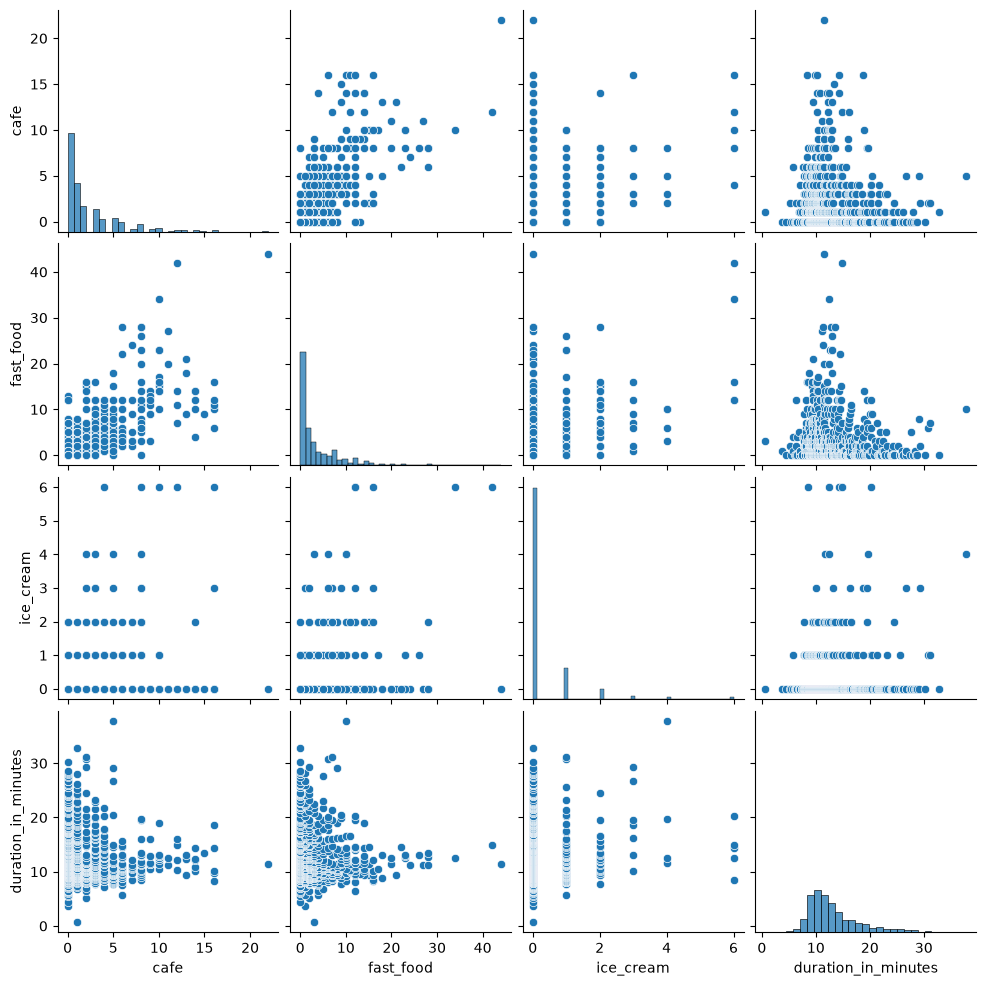

In [35]:
sns.pairplot(df[['cafe', 'fast_food', 'ice_cream', 'duration_in_minutes']])
plt.show()

- при наличии точек интереса поездки, как правило, укладываются в диапазон 7–12 минут.
- при отсутствии точек интереса длительность поездки не ограничена этим диапазоном и варьируется от 2 до 30+ минут.

### Нужно проанализировать, сколько минут аренды набирается в зависимости от наличия рядом:

- кафе (есть / нет)
- фастфуда (есть / нет)
- мороженого (есть / нет)

#### Кафе

- пишу скрипт где подсчитываю сколько было поездок при наличии кафе и нет

In [36]:
s = ride_a_bike_with_food_point['cafe'].gt(0)

result_cafe = (
    s.value_counts()
     .rename({False: 'without_cafe', True: 'with_cafe'})
     .to_frame('count')
     .assign(share=lambda x: x['count'] / x['count'].sum())
)

result_cafe

,count,share
cafe,,
with_cafe,10948309,0.77934
without_cafe,3099873,0.22066


- пишу скрипт где подсчитываю сколько суммарное количество минут при наличии кафе и нет

In [38]:
result_cafe['total_minutes'] = (
    ride_a_bike_with_food_point
    .groupby(ride_a_bike_with_food_point['cafe'].gt(0))['duration_in_minutes']
    .sum()
    .rename({False: 'without_cafe', True: 'with_cafe'})
)

result_cafe

,count,share,total_minutes
cafe,,,
with_cafe,10948309,0.77934,250229488.0
without_cafe,3099873,0.22066,98440216.0


- строю два графика где:
    - количество поездок при наличии кафе и нет
    - суммарное время аренды при наличии кафе и нет 

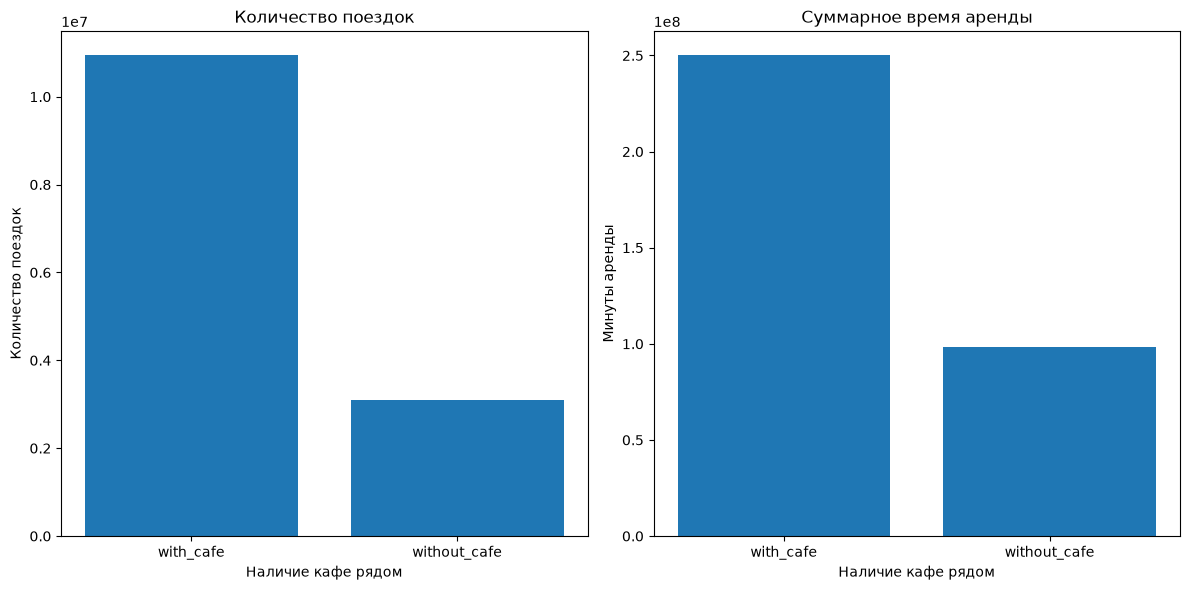

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.bar(
    result_cafe.index,
    result_cafe['count']
)
ax1.set_title('Количество поездок')
ax1.set_xlabel('Наличие кафе рядом')
ax1.set_ylabel('Количество поездок')

ax2.bar(
    result_cafe.index,
    result_cafe['total_minutes']
)
ax2.set_title('Суммарное время аренды')
ax2.set_xlabel('Наличие кафе рядом')
ax2.set_ylabel('Минуты аренды')

plt.tight_layout()
plt.show()

#### Фаст фуд

- пишу скрипт где подсчитываю сколько было поездок при наличии фаст фуда и нет

In [41]:
s = ride_a_bike_with_food_point['fast_food'].gt(0)

result_fast_food = (
    s.value_counts()
     .rename({False: 'without_fast_food', True: 'with_fast_food'})
     .to_frame('count')
     .assign(share=lambda x: x['count'] / x['count'].sum())
)

result_fast_food

,count,share
fast_food,,
with_fast_food,11301117,0.804454
without_fast_food,2747065,0.195546


- пишу скрипт где подсчитываю сколько суммарное количество минут при наличии кафе и нет

In [43]:
result_fast_food['total_minutes'] = (
    ride_a_bike_with_food_point
    .groupby(ride_a_bike_with_food_point['fast_food'].gt(0))['duration_in_minutes']
    .sum()
    .rename({False: 'without_fast_food', True: 'with_fast_food'})
)

result_fast_food

,count,share,total_minutes
fast_food,,,
with_fast_food,11301117,0.804454,267520800.0
without_fast_food,2747065,0.195546,81148912.0


- строю два графика где:
    - количество поездок при наличии фаст фуда и нет
    - суммарное время аренды при наличии фаст фуда и нет 

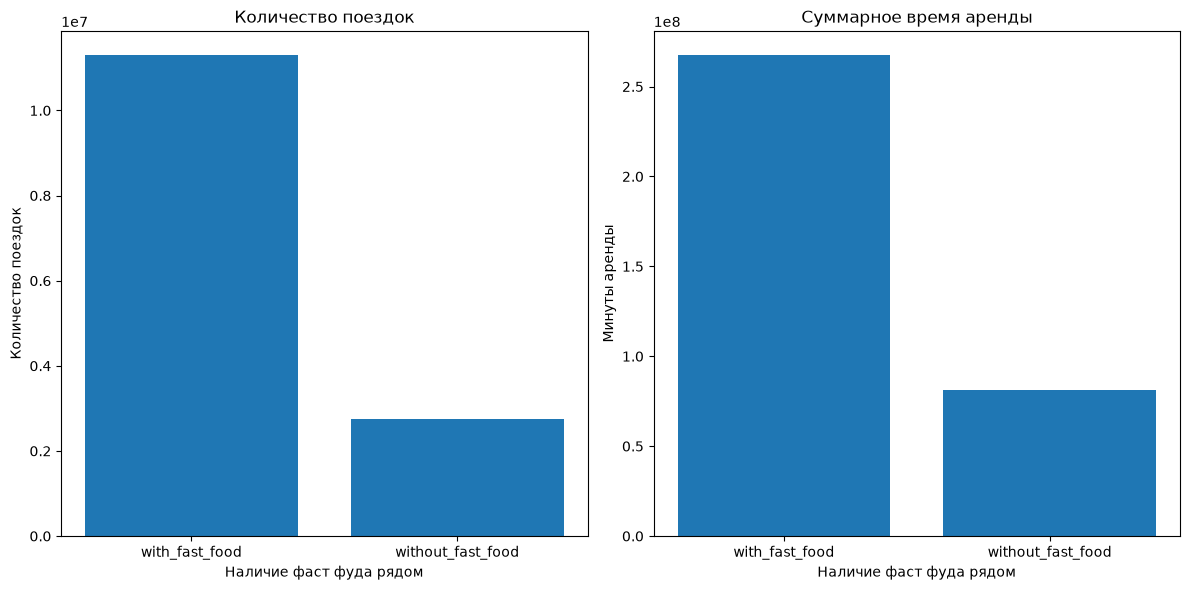

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.bar(
    result_fast_food.index,
    result_fast_food['count']
)
ax1.set_title('Количество поездок')
ax1.set_xlabel('Наличие фаст фуда рядом')
ax1.set_ylabel('Количество поездок')

ax2.bar(
    result_fast_food.index,
    result_fast_food['total_minutes']
)
ax2.set_title('Суммарное время аренды')
ax2.set_xlabel('Наличие фаст фуда рядом')
ax2.set_ylabel('Минуты аренды')

plt.tight_layout()
plt.show()

#### Мороженное

In [45]:
s = ride_a_bike_with_food_point['ice_cream'].gt(0)

result_ice_cream = (
    s.value_counts()
     .rename({False: 'without_ice_cream', True: 'with_ice_cream'})
     .to_frame('count')
     .assign(share=lambda x: x['count'] / x['count'].sum())
)

result_ice_cream

,count,share
ice_cream,,
without_ice_cream,10547800,0.75083
with_ice_cream,3500382,0.24917


In [48]:
result_ice_cream['total_minutes'] = (
    ride_a_bike_with_food_point
    .groupby(ride_a_bike_with_food_point['ice_cream'].gt(0))['duration_in_minutes']
    .sum()
    .rename({False: 'without_ice_cream', True: 'with_ice_cream'})
)

result_ice_cream

,count,share,total_minutes
ice_cream,,,
without_ice_cream,10547800,0.75083,267795712.0
with_ice_cream,3500382,0.24917,80873992.0


- строю два графика где:
    - количество поездок при наличии мороженного и нет
    - суммарное время аренды при наличии мороженного и нет 

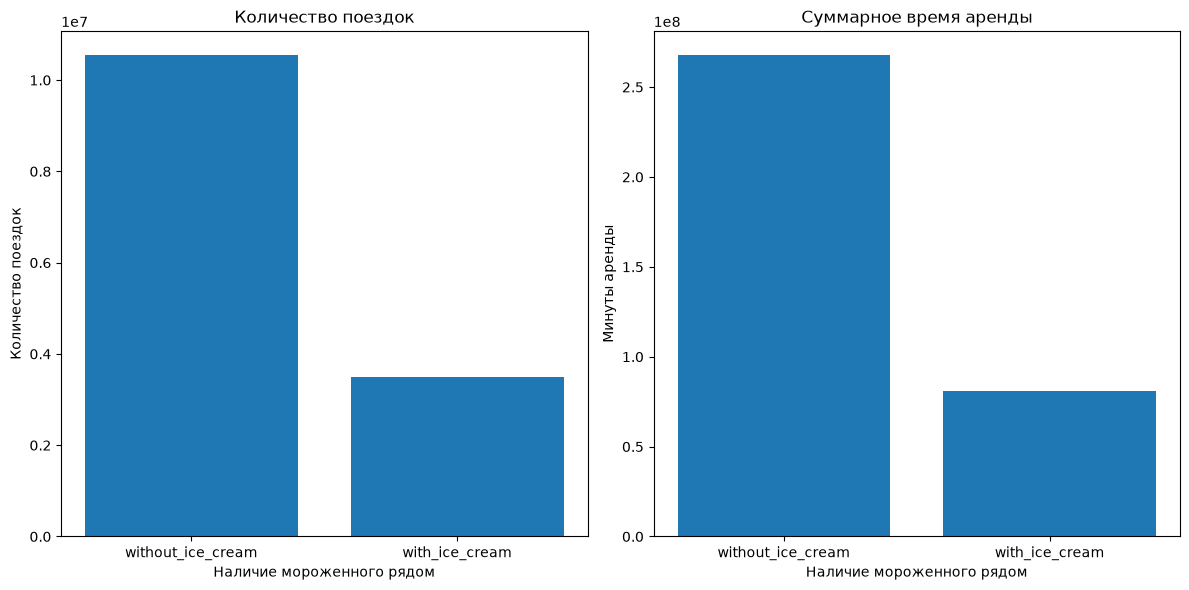

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.bar(
    result_ice_cream.index,
    result_ice_cream['count']
)
ax1.set_title('Количество поездок')
ax1.set_xlabel('Наличие мороженного рядом')
ax1.set_ylabel('Количество поездок')

ax2.bar(
    result_ice_cream.index,
    result_ice_cream['total_minutes']
)
ax2.set_title('Суммарное время аренды')
ax2.set_xlabel('Наличие мороженного рядом')
ax2.set_ylabel('Минуты аренды')

plt.tight_layout()
plt.show()

### Вывод по гипотезе 4 - На сколько можно увеличить прибыль если расположить парковки велосипедов рядом с торговыми точками (будто питание или сервис по велосипедам)

- Точно стоит распологать парковки если есть точки с кафе и фастфудом, так как количество аренды и суммарное количество минут аренды будет в 3 раза выше чем их совсем не будет

- исключение является точки с мороженным, так как их моло в городе 



    
- Также точки интереса будут притягивать людей по разным причинам (будто еда, ПВЗ, магазины или другие)

- Здесь не проводился анализ другие точкек интереса